# Lab 07
## GEOG 6890
### Ashtyn Gluck
#### 10/14/2026

In this lab, we will use the Global Water Quality dataset from [Open Water Quality](https://openwaterquality.org/). This dataset contains surface-water-quality measurements collected from monitoring sites around the world.

The dataset includes information such as date, water-quality measurements, latitude, longitude, water-body type, and data source.

We will use `Pandas` to read, organize, and analyze the data, and `Matplotlib` to create plots and visualize spatial and temporal patterns in water quality.

### 1. Read the csv
Use Pandas pd.read_csv() to read the water-quality dataset into a DataFrame.

In [6]:
import pandas as pd

In [7]:
df = pd.read_csv(
    "open-water-quality_6890.csv",
    skiprows = 6
)
df.head()

,date,indicator,value,unit,latitude,longitude,source,region,water_body
0,1996-03-28,E. coli,0.0,CFU/100mL,30.7902,-88.0864,WQP,Alabama,river/stream
1,1996-04-18,E. coli,0.0,CFU/100mL,30.7854,-88.0881,WQP,Alabama,river/stream
2,1996-04-24,E. coli,0.0,CFU/100mL,30.6536,-87.7918,WQP,Alabama,river/stream
3,1996-04-25,E. coli,0.0,CFU/100mL,30.7902,-88.0864,WQP,Alabama,river/stream
4,1996-05-02,E. coli,0.0,CFU/100mL,30.7902,-88.0864,WQP,Alabama,river/stream


### 2. Explore the Dataset
Explore the structure and contents of the dataset.

In [8]:
#check dimensions
print(df.shape)

#check column names
print(df.columns)

#
print(df.dtypes)

#display first 10 records
print(df.head(10))

#examine the dataset
df.info()

(30387, 9)
Index(['date', 'indicator', 'value', 'unit', 'latitude', 'longitude', 'source',
       'region', 'water_body'],
      dtype='str')
date              str
indicator         str
value         float64
unit              str
latitude      float64
longitude     float64
source            str
region            str
water_body        str
dtype: object
         date indicator    value       unit  latitude  longitude source  \
0  1996-03-28   E. coli   0.0000  CFU/100mL   30.7902   -88.0864    WQP   
1  1996-04-18   E. coli   0.0000  CFU/100mL   30.7854   -88.0881    WQP   
2  1996-04-24   E. coli   0.0000  CFU/100mL   30.6536   -87.7918    WQP   
3  1996-04-25   E. coli   0.0000  CFU/100mL   30.7902   -88.0864    WQP   
4  1996-05-02   E. coli   0.0000  CFU/100mL   30.7902   -88.0864    WQP   
5  1996-05-17   E. coli   0.0000  CFU/100mL   30.7854   -88.0881    WQP   
6  1996-05-19   E. coli   0.0000  CFU/100mL   30.5673   -87.7710    WQP   
7  1996-05-19   E. coli  33.3333  CFU/100mL   

In [9]:
df["value"].describe()

count     30387.000000
mean        519.144396
std        3352.050488
min           0.000000
25%          11.111100
50%          74.900000
75%         233.333300
max      190000.000000
Name: value, dtype: float64

In [10]:
type(df["value"])

pandas.Series

### 3. Select data

For this analysis, we only need four variables: `date`, `value`, `latitude`, and `longitude`.

Create a new DataFrame called df_sub containing only these columns. DO NOT forget make a copy.

In [11]:
df_sub = df[["date", "value", "latitude", "longitude"]].copy() #.copy() creates an independent DataFrame, so we can safely modify the data

In [12]:
type(df_sub)

pandas.DataFrame

In [13]:
df_sub

,date,value,latitude,longitude
0,1996-03-28,0.0,30.7902,-88.0864
1,1996-04-18,0.0,30.7854,-88.0881
2,1996-04-24,0.0,30.6536,-87.7918
3,1996-04-25,0.0,30.7902,-88.0864
4,1996-05-02,0.0,30.7902,-88.0864
...,...,...,...,...
30382,2025-07-07,260.3,34.3026,-86.0203
30383,2025-07-10,2419.6,34.3259,-86.1487
30384,2025-07-10,2419.6,34.3026,-86.0203
30385,2025-07-14,1413.6,34.3026,-86.0203


### 4. Clean the Data
Check the selected variables for missing values and remove incomplete observations.

In [14]:
df_sub.isna().sum() #check missing values

date         0
value        0
latitude     0
longitude    0
dtype: int64

In [15]:
df_sub = df_sub.dropna(subset=["value"]) #if there is a missing value use .dropna to remove it

### 5. Creating plots with Pandas

Pandas provides built-in plotting capabilities that allow you to create various types of plots directly from DataFrames.

<Axes: xlabel='date'>

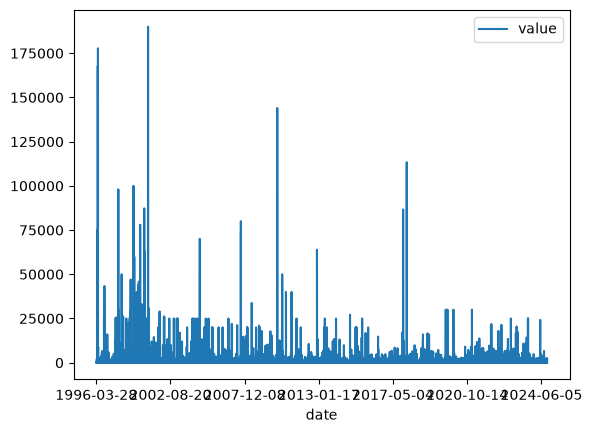

In [16]:
df_sub.plot(x="date", y="value") #time-series line plot

<Axes: title={'center': 'Value over Time'}, xlabel='date'>

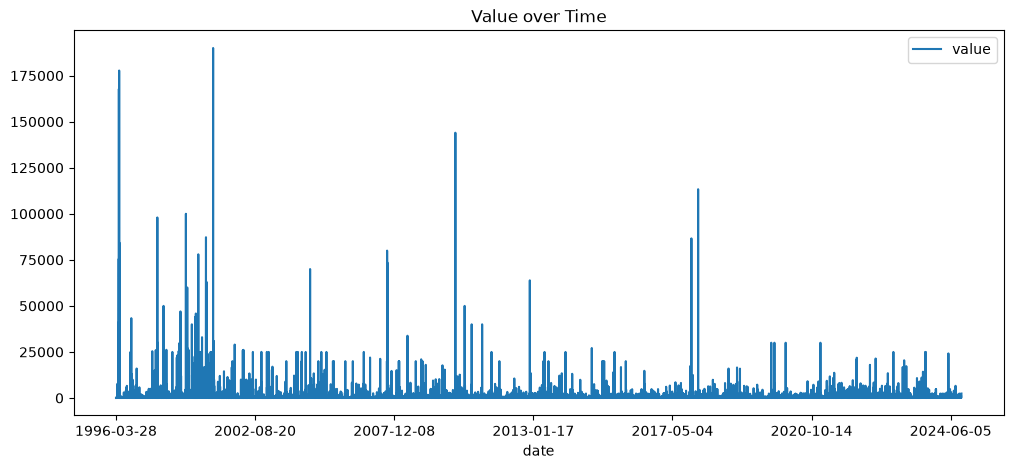

In [17]:
df_sub.plot(
    x="date",
    y="value",
    figsize=(12,5),
    title="Value over Time"
    )

### 6. Convert `Date` to datetime
The `date` column should be converted to Pandas datetime format before performing temporal analysis.

In [18]:
df_sub["date"].dtype

<StringDtype(na_value=nan)>

In [19]:
type(df_sub["date"])

pandas.Series

In [20]:
df_sub["date"] = pd.to_datetime(df_sub["date"])

In [21]:
df_sub["year"] = df_sub["date"].dt.year
df_sub["month"] = df_sub["date"].dt.month
df_sub["day"] = df_sub["date"].dt.day

In [22]:
df_2024 = df_sub[df_sub["date"].dt.year == 2024]
df_2024

,date,value,latitude,longitude,year,month,day
29794,2024-01-10,2.0,34.9983,-88.1989,2024,1,10
29795,2024-01-22,100.0,31.1428,-87.5140,2024,1,22
29796,2024-01-22,22.0,31.1124,-87.3629,2024,1,22
29797,2024-01-22,31.0,31.1559,-87.3626,2024,1,22
29798,2024-01-22,38.0,31.1035,-87.5697,2024,1,22
...,...,...,...,...,...,...,...
30315,2024-10-31,204.6,32.3166,-85.0145,2024,10,31
30316,2024-11-12,150.0,33.4474,-87.1219,2024,11,12
30317,2024-12-18,1.0,35.0042,-85.6974,2024,12,18
30318,2024-12-18,25.9,33.8212,-87.0708,2024,12,18


<Axes: xlabel='date'>

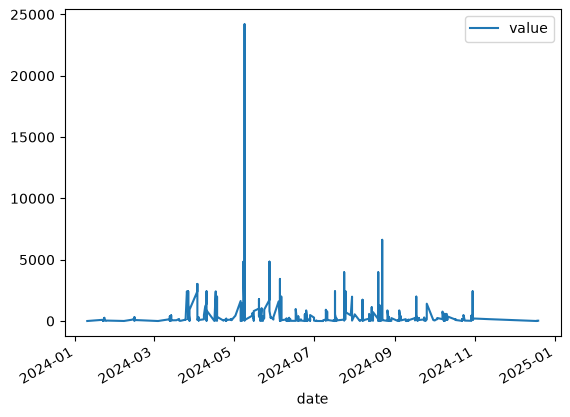

In [23]:
df_2024.plot(x="date", y="value")

### 7. Investigate the Unusually Large Value
The plot may reveal an unusually large observation. Find the maximum value and identify its location.

In [24]:
df_2024["value"].max()

np.float64(24196.0)

In [25]:
max_row = df_2024.loc[df_2024["value"].idxmax()]
print(max_row)

date         2024-05-09 00:00:00
value                    24196.0
latitude                 31.8422
longitude                -85.759
year                        2024
month                          5
day                            9
Name: 29917, dtype: object


### 8. Calculate the distance to Auburn using the Haversine formula
Calculate the distance between the location with the maximum value and Auburn using the Haversine formula.

In [26]:
import numpy as np

#Auburn coordinates
auburn_lat = 32.6099
auburn_lon = -85.4808

#Coordinates of the maximum value
max_lat = max_row["latitude"]
max_lon = max_row["longitude"]

from math import radians, sin, cos, sqrt, atan2

def haversine(lat1, lon1, lat2, lon2):
    R = 3959

    #convert degrees to radians
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    #differences
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    #Haversine formula
    a = (np.sin(dlat / 2)**2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon/2)**2)

    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))

    return R * c

In [27]:
#Calculate distance to Auburn
distance = haversine(
    max_lat,
    max_lon, 
    auburn_lat,
    auburn_lon
)
print(f"Distance to Auburn: {distance:.2f} miles")

Distance to Auburn: 55.48 miles


### 9. Plot a Spatial Scatter Plot of the 2024 Observations

We can use Matplotlib to visualize the spatial distribution of the observations collected in 2024. Here, Longitude is the x-axis and Latitude is the y-axis.

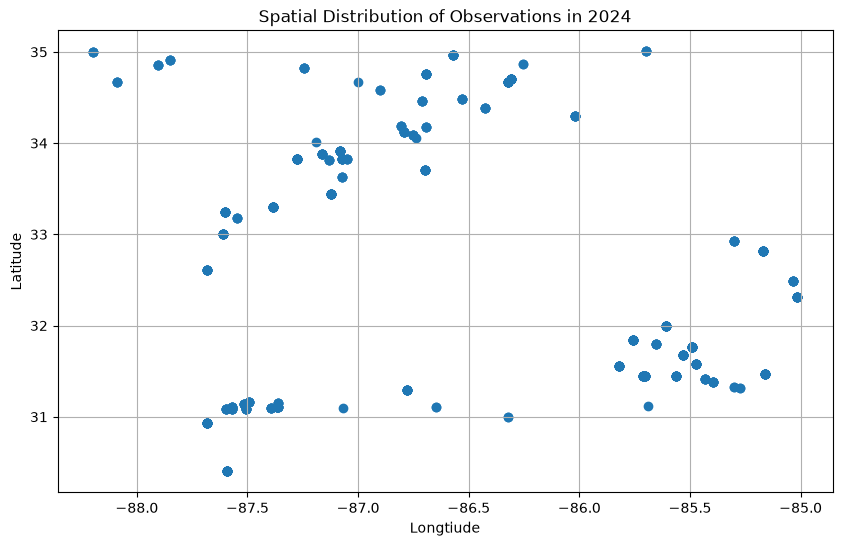

In [28]:
import matplotlib.pyplot as plt

#create a spatial scatterplot
plt.figure(figsize=(10,6))

plt.scatter(
    df_2024["longitude"],
    df_2024["latitude"]
)

#add labels and title
plt.xlabel("Longtiude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of Observations in 2024")

# Add grid
plt.grid(True)
#Display the plot
plt.show()

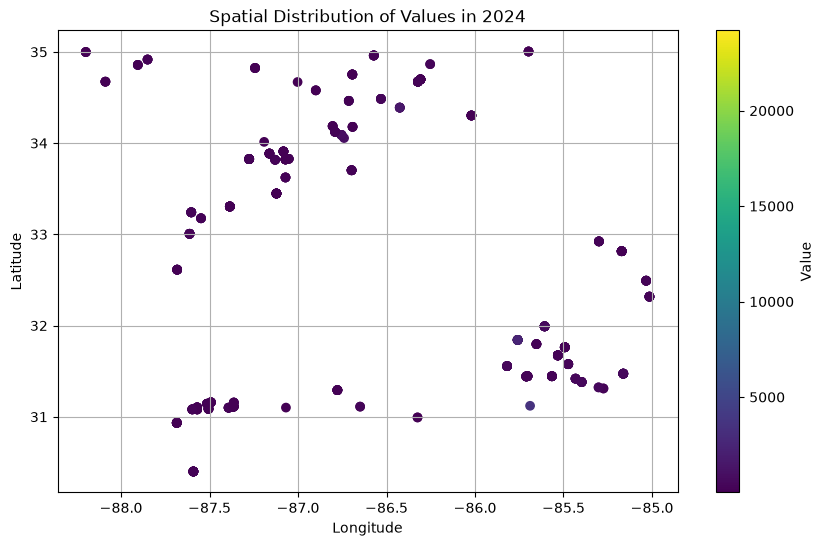

In [29]:
plt.figure(figsize=(10,6))

scatter = plt.scatter(
    df_2024["longitude"],
    df_2024["latitude"],
    c=df_2024["value"],
    cmap="viridis"
)

plt.colorbar(scatter, label="Value")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of Values in 2024")

plt.grid(True)
plt.show()

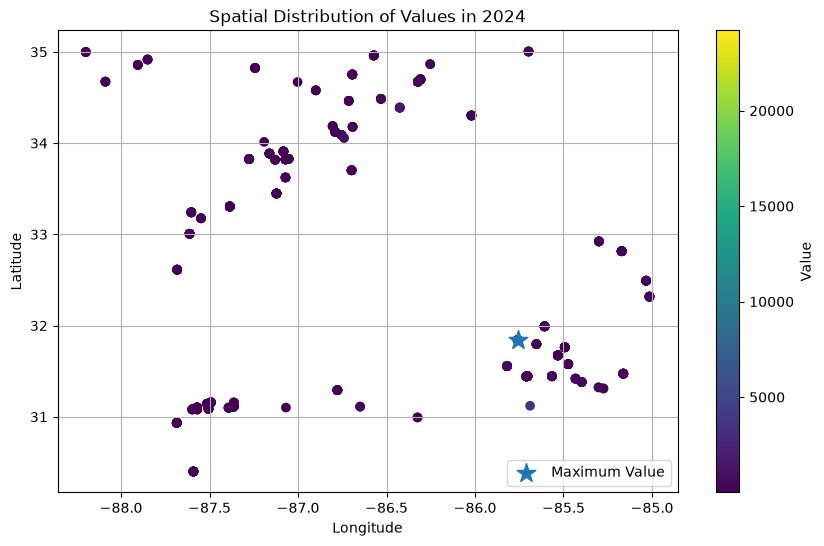

In [30]:
plt.figure(figsize=(10,6))

scatter = plt.scatter(
    df_2024["longitude"],
    df_2024["latitude"],
    c=df_2024["value"],
    cmap="viridis"
)

plt.colorbar(scatter, label="Value")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of Values in 2024")

#Add the location with the maximum value
plt.scatter(
    max_lon,
    max_lat,
    marker="*",
    s=200,
    label="Maximum Value"
)

plt.legend()

plt.grid(True)
plt.show()

# Homework

##  1. Calculate Basic Statistics

Use Pandas to calculate and compare basic statistics for the value column for the years 1996 and 2024.
For each year, calculate:
1. Mean
2. Minimum
3. Maximum
4. Standard deviation

Hint: First select the records for each year, then use the Pandas methods .mean(), .min(), .max(), and .std().

Finally, compare the statistics between 1996 and 2024. Which year has a higher mean value? Which year shows greater variability based on the standard deviation?

In [31]:
import pandas as pd #Use pandas to calculate and compare basic stats for the value column

In [32]:
df_1996 = df_sub[df_sub["date"].dt.year == 1996] #Pulling out the year 1996 from the dataset
df_1996

,date,value,latitude,longitude,year,month,day
0,1996-03-28,0.0000,30.7902,-88.0864,1996,3,28
1,1996-04-18,0.0000,30.7854,-88.0881,1996,4,18
2,1996-04-24,0.0000,30.6536,-87.7918,1996,4,24
3,1996-04-25,0.0000,30.7902,-88.0864,1996,4,25
4,1996-05-02,0.0000,30.7902,-88.0864,1996,5,2
...,...,...,...,...,...,...,...
342,1996-12-27,0.0000,30.3983,-87.7693,1996,12,27
343,1996-12-27,33.3333,30.3830,-87.7972,1996,12,27
344,1996-12-27,33.3333,30.3970,-87.7722,1996,12,27
345,1996-12-28,33.3333,30.5673,-87.7710,1996,12,28


In [33]:
# For each year calculate the mean, minimum, maximum, and standard deviation
mean_values_1996 = df_1996["value"].mean() 
min_values_1996 = df_1996["value"].min()
max_values_1996 = df_1996["value"].max()
sd_values_1996 = df_1996["value"].std()
print(f"The mean E. coli value for 1996 is: {mean_values_1996}")
print(f"The minimum E. coli value for 1996 is: {min_values_1996}")
print(f"The maximum E. coli value for 1996 is: {max_values_1996}")
print(f"The standard deviation for E. coli values for 1996 is: {sd_values_1996}")

The mean E. coli value for 1996 is: 2158.033619596542
The minimum E. coli value for 1996 is: 0.0
The maximum E. coli value for 1996 is: 177766.6667
The standard deviation for E. coli values for 1996 is: 14718.527492754494


In [34]:
df_2024 = df_sub[df_sub["date"].dt.year == 2024] #pulling out the year 2024 from the dataset
df_2024

,date,value,latitude,longitude,year,month,day
29794,2024-01-10,2.0,34.9983,-88.1989,2024,1,10
29795,2024-01-22,100.0,31.1428,-87.5140,2024,1,22
29796,2024-01-22,22.0,31.1124,-87.3629,2024,1,22
29797,2024-01-22,31.0,31.1559,-87.3626,2024,1,22
29798,2024-01-22,38.0,31.1035,-87.5697,2024,1,22
...,...,...,...,...,...,...,...
30315,2024-10-31,204.6,32.3166,-85.0145,2024,10,31
30316,2024-11-12,150.0,33.4474,-87.1219,2024,11,12
30317,2024-12-18,1.0,35.0042,-85.6974,2024,12,18
30318,2024-12-18,25.9,33.8212,-87.0708,2024,12,18


In [35]:
# For each year calculate the mean, minimum, maximum, and standard deviation
mean_values_2024 = df_2024["value"].mean()
min_values_2024 = df_2024["value"].min()
max_values_2024 = df_2024["value"].max()
sd_values_2024 = df_2024["value"].std()
print(f"The mean E. coli value for 2024 is: {mean_values_2024}")
print(f"The minimum E. coli value for 2024 is: {min_values_2024}")
print(f"The maximum E. coli value for 2024 is: {max_values_2024}")
print(f"The standard deviation for E. coli values for 2024 is: {sd_values_2024}")

The mean E. coli value for 2024 is: 400.9505703422053
The minimum E. coli value for 2024 is: 0.5
The maximum E. coli value for 2024 is: 24196.0
The standard deviation for E. coli values for 2024 is: 1237.4455169034457


In [42]:
#Compare the statistics between 1996 and 2024. Which year has a higher mean value? Which year shows greater variability based on the standard deviation?
print(df_1996.describe())
print(df_2024.describe())

                             date          value    latitude   longitude  \
count                         347     347.000000  347.000000  347.000000   
mean   1996-08-29 07:32:20.057636    2158.033620   31.931485  -86.723572   
min           1996-03-28 00:00:00       0.000000   30.364200  -88.367000   
25%           1996-07-07 00:00:00       0.000000   30.780200  -87.772200   
50%           1996-08-16 00:00:00       8.000000   31.389400  -86.276000   
75%           1996-10-29 00:00:00     190.000000   33.490100  -86.048550   
max           1996-12-28 00:00:00  177766.666700   34.801000  -85.507300   
std                           NaN   14718.527493    1.280144    0.926886   

         year       month         day  
count   347.0  347.000000  347.000000  
mean   1996.0    8.435159   16.054755  
min    1996.0    3.000000    1.000000  
25%    1996.0    7.000000   10.000000  
50%    1996.0    8.000000   15.000000  
75%    1996.0   10.000000   23.000000  
max    1996.0   12.000000   31.0000

### Based on the output from the describe function, the mean value for 1996 (2158.03) is larger than 2024 (400.95). It also shows that 1996 has a larger variability with the standard deviation being 14718.53 compared to 2024 being 1237.45. 

## 2 Annual trend and Linear regression

Analyze how the value changes over time.

1. Use Pandas groupby() to calculate the mean value for each year.
2. Create a scatter plot showing Year on the x-axis and Mean Value on the y-axis.
3. Perform a linear regression between Year and Mean Value.
4. Add the linear regression line to your scatter plot.
5. Report the slope, R², and p-value.
6. Based on the slope, describe whether the annual mean shows an increasing or decreasing trend over time.

In [97]:
df_grouped_years = df_sub.groupby("year")["value"].mean()
print(f"Average value of E. coli per year: {df_grouped_years}")

Average value of E. coli per year: year
1996    2158.033620
1997     660.741291
1998     226.843579
1999    1109.127868
2000    1433.560306
2001    1023.365265
2002     406.547411
2003     390.399656
2004     733.352271
2005     352.527940
2006     383.299935
2007     482.763744
2008     422.917902
2009     454.404682
2010     495.217253
2011     336.126421
2012     332.432139
2013     382.639466
2014     290.912034
2015     391.489966
2016     253.475761
2017     508.190833
2018     382.742672
2019     343.223057
2020     254.687827
2021     589.979050
2022     578.392220
2023     367.388987
2024     400.950570
2025     303.198507
Name: value, dtype: float64


In [98]:
print(type(df_grouped_years))
print(df_grouped_years.head())

<class 'pandas.Series'>
year
1996    2158.033620
1997     660.741291
1998     226.843579
1999    1109.127868
2000    1433.560306
Name: value, dtype: float64


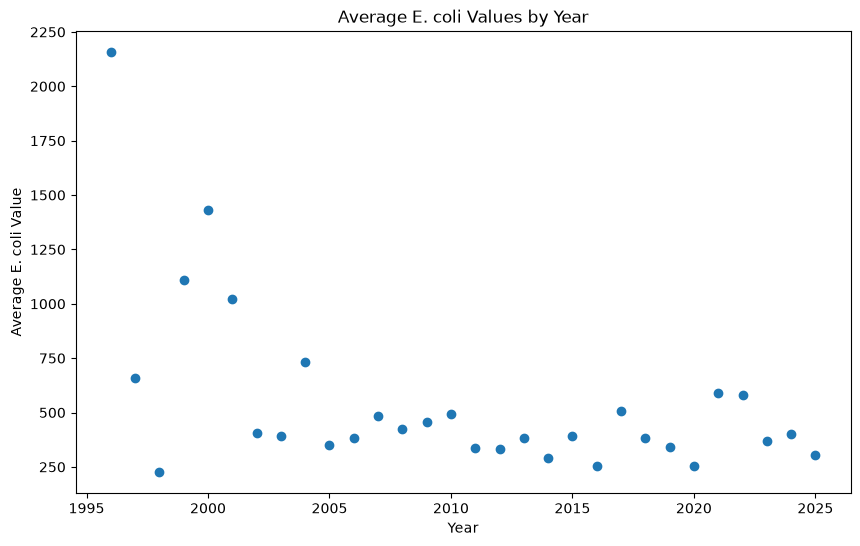

In [99]:
import matplotlib.pyplot as plt

#Create a scatter plot showing Year on the x-axis and Mean Value on the y-axis.
plot = df_grouped_years.plot(style = "o", figsize=(10,6))

plot.set_xlabel("Year")
plot.set_ylabel("Average E. coli Value")
plot.set_title("Average E. coli Values by Year")
plt.show()


In [100]:
#Perform a linear regression between Year and Mean Value
from scipy import stats

x = df_grouped_years.index
y = df_grouped_years.values

result = stats.linregress(x, y)

print(f"Slope: {result.slope:.3f}")
print(f"Intercept: {result.intercept:.3f}")
print(f"R-squared: {result.rvalue**2:.3f}")
print(f"p-value: {result.pvalue:.4f}")

Slope: -24.254
Intercept: 49310.917
R-squared: 0.277
p-value: 0.0028


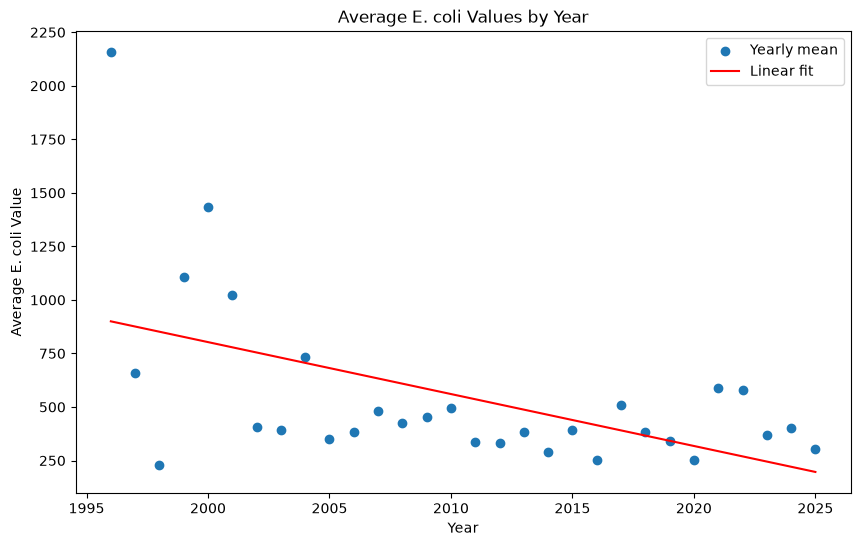

In [101]:
plt.figure(figsize=(10,6))
plt.scatter(x, y, label="Yearly mean")
plt.plot(x, result.intercept + result.slope * x, color="red", label="Linear fit")

plt.xlabel("Year")
plt.ylabel("Average E. coli Value")
plt.title("Average E. coli Values by Year")
plt.legend()
plt.show()

### Based on the slope, the annual mean is showing a decreasing trend over time, as the linear line is going down while the years go up.